<a href="https://colab.research.google.com/github/Haidermushtaq/Computer-Vision-/blob/main/Regression_Algorithms_Comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 0. Setup

Install XGBoost (Colab usually has the rest). Run this cell first.

In [1]:
# Colab already has numpy, pandas, scikit-learn, matplotlib.
# XGBoost is usually preinstalled on Colab too; this line is just a safety net.
!pip install -q xgboost

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
plt.rcParams["figure.figsize"] = (7, 5)
print("Libraries loaded.")

Libraries loaded.


In [3]:
n = 1000  # number of houses

area          = np.round(np.random.uniform(0.8, 4.0, n), 2)     # 1000 sqft
bedrooms      = np.random.randint(1, 6, n)
bathrooms     = np.random.randint(1, 4, n)
age           = np.random.randint(0, 50, n)
distance_city = np.round(np.random.uniform(1, 30, n), 1)        # km
garage        = np.random.randint(0, 3, n)

# True underlying price relationship (unknown to the models) + noise.
# It mixes linear terms with real nonlinearity, an interaction, and two
# step (threshold) effects. That is what gives the tree ensembles and the
# neural network an edge over plain linear regression.
price = (
    50
    + 70 * area                      # linear: bigger house -> higher price
    + 10 * bedrooms
    + 15 * bathrooms
    - 0.8 * age
    - 2.0 * distance_city
    + 8 * garage
    + 14 * (area ** 2)               # nonlinearity: curvature in area
    + 9 * area * bathrooms           # interaction: area and bathrooms together
    + 30 * (distance_city < 5)       # step: premium for being near the city
    + 25 * (age < 5)                 # step: premium for a nearly new house
    + np.random.normal(0, 15, n)     # random noise
)
price = np.round(price, 1)

df = pd.DataFrame({
    "area": area,
    "bedrooms": bedrooms,
    "bathrooms": bathrooms,
    "age": age,
    "distance_city": distance_city,
    "garage": garage,
    "price": price,
})

print("Shape:", df.shape)
df.head()

Shape: (1000, 7)


,area,bedrooms,bathrooms,age,distance_city,garage,price
0,2.00,4,3,39,15.4,0,321.6
1,3.84,3,2,21,22.5,1,601.1
2,3.14,5,3,23,10.5,2,556.0
3,2.72,1,2,18,26.8,1,373.6
4,1.30,5,1,36,3.4,0,227.0


In [4]:
df.describe().round(2)

,area,bedrooms,bathrooms,age,distance_city,garage,price
count,1000.00,1000.00,1000.00,1000.0,1000.00,1000.00,1000.00
mean,2.37,3.04,1.99,24.3,15.52,1.02,373.32
std,0.93,1.43,0.82,14.3,8.27,0.82,150.77
min,0.81,1.00,1.00,0.0,1.00,0.00,70.20
25%,1.56,2.00,1.00,12.0,8.40,0.00,250.00
50%,2.39,3.00,2.00,24.0,15.65,1.00,357.85
75%,3.18,4.00,3.00,36.0,22.80,2.00,490.02
max,4.00,5.00,3.00,49.0,29.90,2.00,745.90


### Quick look at the data

A couple of plots to confirm the signal is there (bigger area means higher price, older means a bit cheaper).

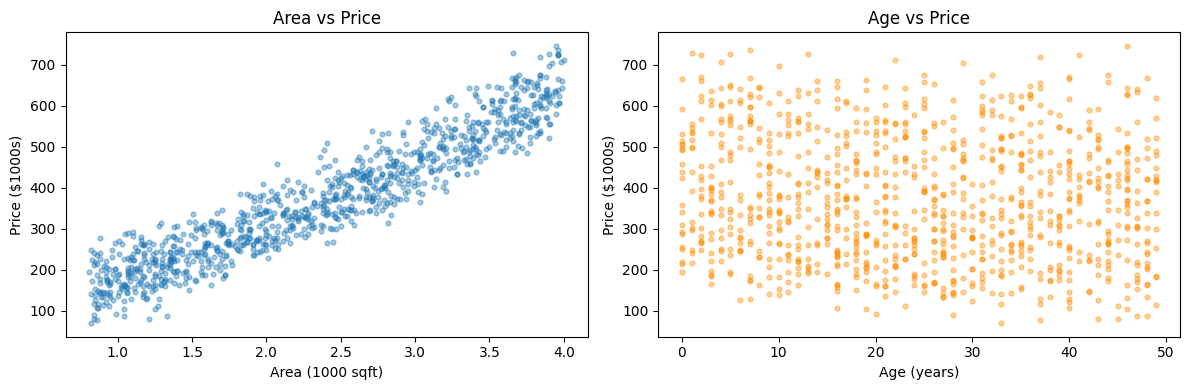

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(df["area"], df["price"], alpha=0.4, s=12)
ax[0].set_xlabel("Area (1000 sqft)"); ax[0].set_ylabel("Price ($1000s)")
ax[0].set_title("Area vs Price")
ax[1].scatter(df["age"], df["price"], alpha=0.4, s=12, color="darkorange")
ax[1].set_xlabel("Age (years)"); ax[1].set_ylabel("Price ($1000s)")
ax[1].set_title("Age vs Price")
plt.tight_layout(); plt.show()

## 2. Preprocessing, train/test split and feature scaling

- **Features and target** are separated.
- An **80:20 split** is used (same split object for every model, so the comparison is fair).
- **Feature scaling** (standardization) is applied. Some models need it badly (KNN, Neural Network), some do not care (tree models). We keep both versions ready so each model gets the input it prefers, while the split stays identical.

Standardization formula for each feature:

$$ x_{scaled} = \frac{x - \mu}{\sigma} $$

where $\mu$ is the training mean and $\sigma$ is the training standard deviation. The scaler is **fit on the training set only** and then applied to the test set, to avoid leaking test information.

In [6]:
feature_cols = ["area", "bedrooms", "bathrooms", "age", "distance_city", "garage"]
X = df[feature_cols].values
y = df["price"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

# Scaled versions (fit on train only)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train size:", X_train.shape[0], " Test size:", X_test.shape[0])

Train size: 800  Test size: 200


In [7]:
results = []  # collect every model's scores here

def evaluate(name, y_true, y_pred, store=True):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    if store:
        results.append({"Model": name, "MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2})
    print(f"{name:22s}  MAE={mae:7.2f}  MSE={mse:9.2f}  RMSE={rmse:7.2f}  R2={r2:6.3f}")
    return mae, mse, rmse, r2

predictions = {}  # name -> predicted test array, for the actual vs predicted plots

## 3. The small sample used for all handwritten calculations

For the handwritten parts we use a tiny 5 house sample so the arithmetic stays doable by hand. Two inputs are used where helpful: **Area** (1000 sqft) and **Bedrooms**.

| House | Area (x) | Bedrooms | Price (y, \$1000s) |
|:---:|:---:|:---:|:---:|
| H1 | 1.0 | 2 | 200 |
| H2 | 1.5 | 3 | 250 |
| H3 | 2.0 | 3 | 305 |
| H4 | 2.5 | 4 | 360 |
| H5 | 3.0 | 4 | 410 |

Useful running totals (single feature Area vs Price):

$$ n=5,\quad \sum x = 10,\quad \bar{x}=2,\quad \sum y = 1525,\quad \bar{y}=305 $$
$$ \sum xy = 3315,\quad \sum x^2 = 22.5 $$

In [8]:
lin = LinearRegression()
lin.fit(X_train_scaled, y_train)      # scaling is harmless here, keeps things uniform
y_pred = lin.predict(X_test_scaled)

predictions["Linear Regression"] = y_pred
evaluate("Linear Regression", y_test, y_pred)

# Show the learned coefficients (on scaled features)
coef_table = pd.DataFrame({"feature": feature_cols, "coefficient": lin.coef_.round(2)})
print("\nIntercept:", round(lin.intercept_, 2))
coef_table

Linear Regression       MAE=  17.92  MSE=   510.34  RMSE=  22.59  R2= 0.975

Intercept: 376.74


,feature,coefficient
0,area,145.19
1,bedrooms,13.11
2,bathrooms,31.03
3,age,-15.32
4,distance_city,-22.75
5,garage,5.92


In [9]:
tree = DecisionTreeRegressor(max_depth=6, random_state=RANDOM_STATE)
tree.fit(X_train, y_train)            # trees do not need scaling
y_pred = tree.predict(X_test)

predictions["Decision Tree"] = y_pred
evaluate("Decision Tree", y_test, y_pred)

Decision Tree           MAE=  27.99  MSE=  1314.17  RMSE=  36.25  R2= 0.934


(27.99480084361411,
 1314.1655437748818,
 np.float64(36.25142126558463),
 0.9343537645137033)

In [10]:
rf = RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

predictions["Random Forest"] = y_pred
evaluate("Random Forest", y_test, y_pred)

# Feature importances are a nice by-product
imp = pd.DataFrame({"feature": feature_cols,
                    "importance": rf.feature_importances_.round(3)}
                   ).sort_values("importance", ascending=False)
imp

Random Forest           MAE=  18.20  MSE=   508.94  RMSE=  22.56  R2= 0.975


,feature,importance
0,area,0.910
2,bathrooms,0.037
4,distance_city,0.031
3,age,0.014
1,bedrooms,0.006
5,garage,0.002


In [11]:
nn = MLPRegressor(hidden_layer_sizes=(64, 32),
                  activation="relu",
                  solver="adam",
                  max_iter=1500,
                  random_state=RANDOM_STATE,
                  early_stopping=True)
nn.fit(X_train_scaled, y_train)       # neural nets need scaled inputs
y_pred = nn.predict(X_test_scaled)

predictions["Neural Network"] = y_pred
evaluate("Neural Network", y_test, y_pred)

Neural Network          MAE=  24.64  MSE=   959.45  RMSE=  30.97  R2= 0.952


(24.637936930789955,
 959.4496873762943,
 np.float64(30.974984864827526),
 0.9520728112123238)

In [12]:
xgb = XGBRegressor(n_estimators=400,
                   learning_rate=0.05,
                   max_depth=4,
                   subsample=0.9,
                   colsample_bytree=0.9,
                   random_state=RANDOM_STATE,
                   n_jobs=-1)
xgb.fit(X_train, y_train)             # XGBoost does not need scaling
y_pred = xgb.predict(X_test)

predictions["XGBoost"] = y_pred
evaluate("XGBoost", y_test, y_pred)

XGBoost                 MAE=  13.42  MSE=   280.08  RMSE=  16.74  R2= 0.986


(13.420972381591795,
 280.07659023727734,
 np.float64(16.735488945270685),
 0.9860093928926926)

In [13]:
knn = KNeighborsRegressor(n_neighbors=7)
knn.fit(X_train_scaled, y_train)      # KNN depends heavily on scaling
y_pred = knn.predict(X_test_scaled)

predictions["KNN"] = y_pred
evaluate("KNN", y_test, y_pred)

KNN                     MAE=  30.92  MSE=  1610.07  RMSE=  40.13  R2= 0.920


(30.918500000000005,
 1610.0726724489796,
 np.float64(40.12571086534143),
 0.9195723778436375)

---
## 10. Comparative performance table

All six models, same split, same features, scored on the same test set. Lower MAE / MSE / RMSE is better; higher R2 is better.

In [14]:
results_df = pd.DataFrame(results).set_index("Model")
results_df = results_df.round({"MAE": 2, "MSE": 2, "RMSE": 2, "R2": 4})
results_df_sorted = results_df.sort_values("RMSE")  # best (lowest RMSE) on top
results_df_sorted

,MAE,MSE,RMSE,R2
Model,,,,
XGBoost,13.42,280.08,16.74,0.9860
Random Forest,18.20,508.94,22.56,0.9746
Linear Regression,17.92,510.34,22.59,0.9745
Neural Network,24.64,959.45,30.97,0.9521
Decision Tree,27.99,1314.17,36.25,0.9344
KNN,30.92,1610.07,40.13,0.9196


In [15]:
# Highlight the best model on each metric
best = {
    "Lowest MAE":  results_df["MAE"].idxmin(),
    "Lowest MSE":  results_df["MSE"].idxmin(),
    "Lowest RMSE": results_df["RMSE"].idxmin(),
    "Highest R2":  results_df["R2"].idxmax(),
}
for k, v in best.items():
    print(f"{k:14s}: {v}")

Lowest MAE    : XGBoost
Lowest MSE    : XGBoost
Lowest RMSE   : XGBoost
Highest R2    : XGBoost


### Bar charts of the metrics

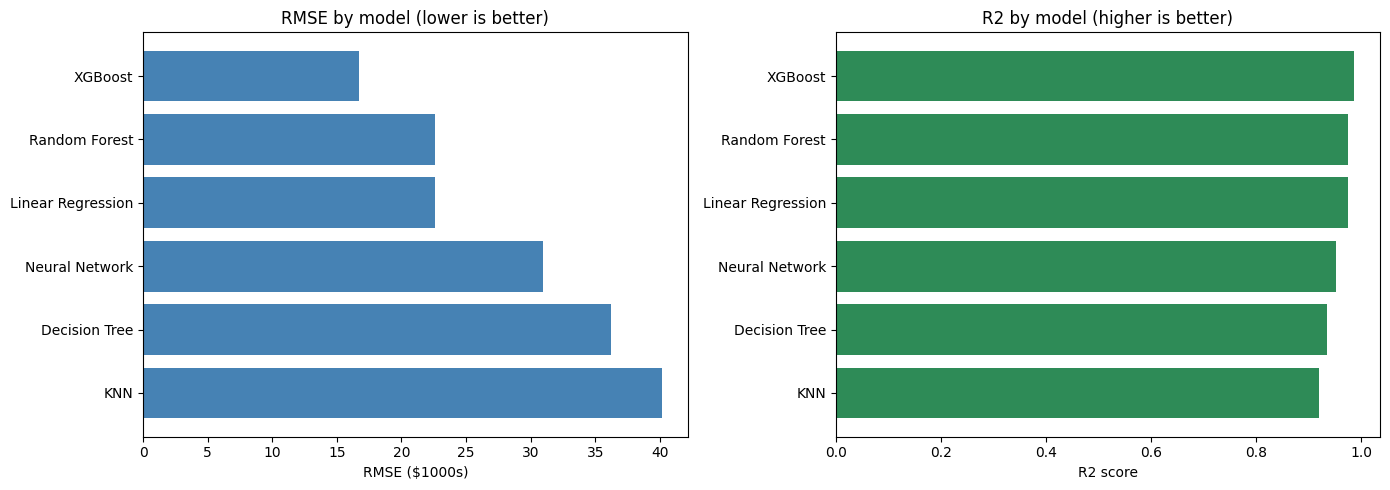

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

order = results_df_sorted.index
axes[0].barh(order, results_df_sorted["RMSE"], color="steelblue")
axes[0].set_title("RMSE by model (lower is better)")
axes[0].set_xlabel("RMSE ($1000s)")
axes[0].invert_yaxis()

axes[1].barh(order, results_df_sorted["R2"], color="seagreen")
axes[1].set_title("R2 by model (higher is better)")
axes[1].set_xlabel("R2 score")
axes[1].invert_yaxis()

plt.tight_layout(); plt.show()

## 11. Actual vs predicted plots

For a perfect model every point sits on the red diagonal. The tighter the cloud hugs the line, the better the model.

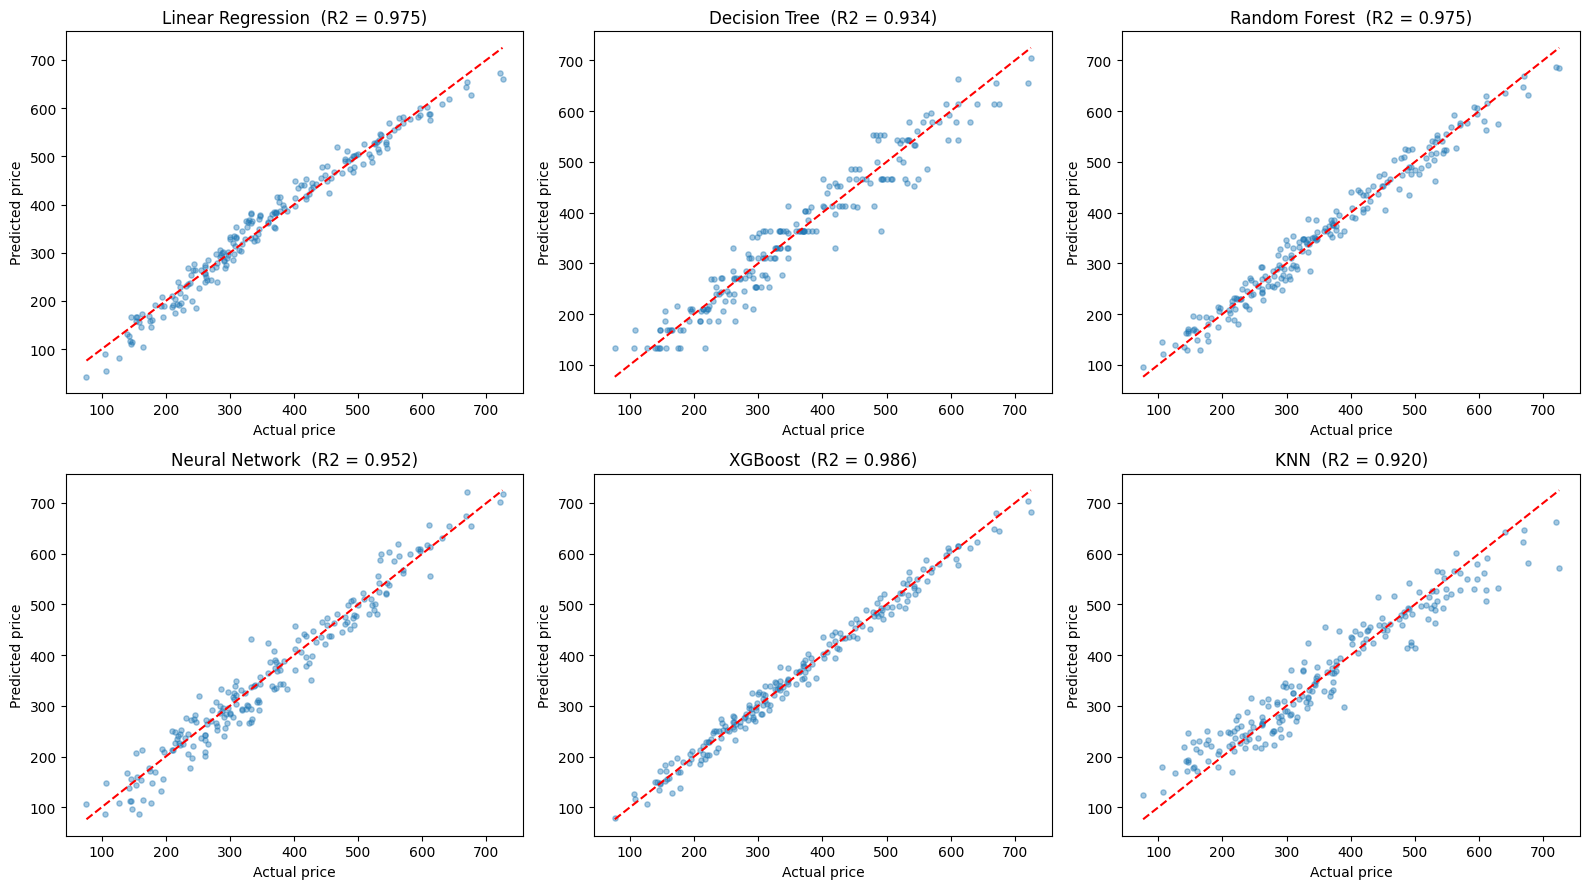

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.ravel()
lo, hi = y_test.min(), y_test.max()

for ax, (name, y_pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, y_pred, alpha=0.4, s=14)
    ax.plot([lo, hi], [lo, hi], "r--", linewidth=1.5)
    r2 = r2_score(y_test, y_pred)
    ax.set_title(f"{name}  (R2 = {r2:.3f})")
    ax.set_xlabel("Actual price")
    ax.set_ylabel("Predicted price")

plt.tight_layout(); plt.show()

In [18]:
best_model = results_df["RMSE"].idxmin()
best_row = results_df.loc[best_model]

print("="*55)
print("CONCLUSION")
print("="*55)
print(f"Best performing model (lowest RMSE): {best_model}")
print(f"  MAE  = {best_row['MAE']:.2f}")
print(f"  MSE  = {best_row['MSE']:.2f}")
print(f"  RMSE = {best_row['RMSE']:.2f}")
print(f"  R2   = {best_row['R2']:.4f}")
print()
print("Ranking by RMSE (best to worst):")
for i, (name, row) in enumerate(results_df.sort_values('RMSE').iterrows(), 1):
    print(f"  {i}. {name:20s}  RMSE={row['RMSE']:7.2f}  R2={row['R2']:.3f}")

CONCLUSION
Best performing model (lowest RMSE): XGBoost
  MAE  = 13.42
  MSE  = 280.08
  RMSE = 16.74
  R2   = 0.9860

Ranking by RMSE (best to worst):
  1. XGBoost               RMSE=  16.74  R2=0.986
  2. Random Forest         RMSE=  22.56  R2=0.975
  3. Linear Regression     RMSE=  22.59  R2=0.975
  4. Neural Network        RMSE=  30.97  R2=0.952
  5. Decision Tree         RMSE=  36.25  R2=0.934
  6. KNN                   RMSE=  40.13  R2=0.920
